In [1]:
!pip install ortools pandas openpyxl matplotlib


In [2]:
from __future__ import annotations

from collections import defaultdict
from dataclasses import dataclass
from math import ceil
from pathlib import Path
from typing import Dict, List, Set, Tuple

import pandas as pd
from ortools.sat.python import cp_model


@dataclass(frozen=True)
class SubjectInfo:
    subject: str
    min_size: int
    max_size: int
    count: int


@dataclass(frozen=True)
class Section:
    section_id: str
    subject: str
    min_size: int
    max_size: int


@dataclass(frozen=True)
class Session:
    session_id: str
    section_id: str
    subject: str
    session_no: str
    duration: int


@dataclass(frozen=True)
class Block:
    block_id: str
    duration: int
    slot_ids: Tuple[str, ...]


def read_sheet_flexible(
    xls: pd.ExcelFile,
    sheet_name: str,
    required_columns: Set[str],
    optional: bool = False,
) -> pd.DataFrame:
    if sheet_name not in xls.sheet_names:
        if optional:
            return pd.DataFrame(columns=list(required_columns))
        raise ValueError(f"필수 시트가 없습니다: {sheet_name}")

    for header_row in range(0, 5):
        df = pd.read_excel(xls, sheet_name=sheet_name, header=header_row)
        df.columns = [str(c).strip() for c in df.columns]
        if required_columns.issubset(set(df.columns)):
            return df

    if optional:
        return pd.DataFrame(columns=list(required_columns))
    raise ValueError(f"{sheet_name} 시트에 필요한 컬럼이 없습니다: {required_columns}")


def normalize_str_columns(df: pd.DataFrame, cols: List[str]) -> pd.DataFrame:
    out = df.copy()
    for c in cols:
        if c in out.columns:
            out[c] = out[c].fillna("").astype(str).str.strip()
    return out


def split_list_cell(value) -> List[str]:
    if pd.isna(value):
        return []
    text = str(value).strip()
    if not text:
        return []
    text = text.replace("|", ",")
    return [x.strip() for x in text.split(",") if x.strip()]


def is_selected(value) -> bool:
    if pd.isna(value):
        return False
    text = str(value).strip().lower()
    return text in {"1", "1.0", "true", "t", "yes", "y", "o", "○", "✓", "v"}



def parse_enrollments(enroll_df: pd.DataFrame) -> pd.DataFrame:
    """
    Enrollments 시트를 표준 형태(student_id, subject, weight)로 변환한다.

    지원 형식 1: long format
        student_id | subject | weight
        1-1        | Math    | 23

    지원 형식 2: wide format
        student_id | Math | Physics | ...
        S001       | 1    | 0       | ...
        1-1        | 23   | 23      | ...
    """
    enroll_df = normalize_str_columns(enroll_df, ["student_id", "subject"])

    def parse_weight(value) -> int:
        if pd.isna(value):
            return 0

        text = str(value).strip()
        if not text:
            return 0

        lower = text.lower()
        if lower in {"true", "t", "yes", "y", "o", "○", "✓", "v"}:
            return 1

        try:
            number = float(text)
        except ValueError as exc:
            raise ValueError(f"Enrollments의 값은 숫자 또는 체크 표시여야 합니다: {value}") from exc

        if number <= 0:
            return 0

        if not number.is_integer():
            raise ValueError(f"Enrollments의 인원수는 정수여야 합니다: {value}")

        return int(number)

    # 1) long format: student_id, subject 또는 student_id, subject, weight
    if "subject" in enroll_df.columns:
        out = enroll_df[["student_id", "subject"]].copy()

        if "weight" in enroll_df.columns:
            out["weight"] = enroll_df["weight"].apply(parse_weight)
        elif "count" in enroll_df.columns:
            out["weight"] = enroll_df["count"].apply(parse_weight)
        elif "num_students" in enroll_df.columns:
            out["weight"] = enroll_df["num_students"].apply(parse_weight)
        else:
            out["weight"] = 1

        out = out[out["student_id"].astype(str).str.strip() != ""]
        out = out[out["subject"].astype(str).str.strip() != ""]
        out = out[out["weight"] > 0]

        return (
            out.groupby(["student_id", "subject"], as_index=False)["weight"]
            .sum()
            .reset_index(drop=True)
        )

    # 2) wide format: student_id, 과목A, 과목B, ...
    if "student_id" not in enroll_df.columns:
        raise ValueError("Enrollments에는 student_id 컬럼이 필요합니다.")

    subject_cols = [c for c in enroll_df.columns if str(c).strip() != "student_id"]
    rows = []

    for _, row in enroll_df.iterrows():
        student = str(row["student_id"]).strip()
        if not student:
            continue

        for subj in subject_cols:
            weight = parse_weight(row[subj])
            if weight > 0:
                rows.append({
                    "student_id": student,
                    "subject": str(subj).strip(),
                    "weight": weight,
                })

    if not rows:
        raise ValueError("Enrollments에서 수강신청 데이터가 비어 있습니다.")

    out = pd.DataFrame(rows)

    return (
        out.groupby(["student_id", "subject"], as_index=False)["weight"]
        .sum()
        .reset_index(drop=True)
    )

def make_slots_from_days(days_df: pd.DataFrame) -> Tuple[List[str], Dict[str, List[int]]]:
    """
    Days 형식:
    day | periods
    Mon | 1|2|3|4|5|6|7

    또는:
    day | num_periods
    Mon | 7
    """
    days_df = normalize_str_columns(days_df, ["day", "periods"])
    day_periods: Dict[str, List[int]] = {}

    for _, row in days_df.iterrows():
        day = str(row["day"]).strip()
        if not day:
            continue

        if "periods" in days_df.columns and str(row.get("periods", "")).strip():
            periods = [
                int(x.strip())
                for x in str(row["periods"]).replace(",", "|").split("|")
                if x.strip()
            ]
        elif "num_periods" in days_df.columns:
            periods = list(range(1, int(row["num_periods"]) + 1))
        else:
            raise ValueError("Days 시트에는 periods 또는 num_periods 컬럼이 필요합니다.")

        day_periods[day] = periods

    slot_ids = [f"{day}{p}" for day, periods in day_periods.items() for p in periods]
    return slot_ids, day_periods


def generate_blocks(day_periods: Dict[str, List[int]], needed_durations: Set[int]) -> Dict[str, Block]:
    """
    같은 요일 내부의 연속 블록을 자동 생성한다.
    기본값: 4-5교시를 같은 연강 블록으로 묶지 않는다. (점심시간)
    """
    blocks: Dict[str, Block] = {}

    # 같은 블록 안에 함께 들어가면 안 되는 연속 교시쌍
    forbidden_adjacent_pairs = {(4, 5)}

    for day, periods in day_periods.items():
        periods = sorted(periods)
        period_set = set(periods)

        for dur in sorted(needed_durations):
            if dur <= 0:
                raise ValueError("duration은 양수여야 합니다.")

            for start in periods:
                seq = list(range(start, start + dur))

                if not all(p in period_set for p in seq):
                    continue

                if any(
                    (seq[i], seq[i + 1]) in forbidden_adjacent_pairs
                    for i in range(len(seq) - 1)
                ):
                    continue

                slots = tuple(f"{day}{p}" for p in seq)
                block_id = f"{day}{start}" if dur == 1 else f"{day}{start}_{start + dur - 1}"
                blocks[block_id] = Block(block_id, dur, slots)

    return blocks


def parse_slot(slot: str) -> Tuple[str, int]:
    slot = str(slot).strip()
    i = 0
    while i < len(slot) and not slot[i].isdigit():
        i += 1
    return slot[:i], int(slot[i:])


def is_immediately_after(prev_block: Block, next_block: Block) -> bool:
    # prev_block 바로 뒤에 next_block이 붙는지 판단.
    prev_day, prev_end = parse_slot(prev_block.slot_ids[-1])
    next_day, next_start = parse_slot(next_block.slot_ids[0])
    return prev_day == next_day and next_start == prev_end + 1


def are_blocks_on_same_day(block_a: Block, block_b: Block) -> bool:
    # 두 block이 같은 요일에 배치되는지 판단한다.
    day_a, _ = parse_slot(block_a.slot_ids[0])
    day_b, _ = parse_slot(block_b.slot_ids[0])
    return day_a == day_b


def block_contains_any_slot(block: Block, blocked_slots: Set[str]) -> bool:
    # block이 blocked_slots 중 하나라도 포함하면 True.
    return any(slot in blocked_slots for slot in block.slot_ids)


def expand_unavailable_slots(row, slot_set: Set[str], day_periods: Dict[str, List[int]]) -> Set[str]:
    """
    TeacherUnavailable / SessionUnavailable에서 slot_id, day 모두 지원.
    slot_id = Mon1 또는 Mon1|Tue2
    day = Mon 또는 Mon|Wed
    둘 다 있으면 합집합 처리.
    """
    result = set()

    if "slot_id" in row.index:
        for slot in split_list_cell(row.get("slot_id", "")):
            if slot not in slot_set:
                raise ValueError(f"존재하지 않는 slot_id입니다: {slot}")
            result.add(slot)

    if "day" in row.index:
        for day in split_list_cell(row.get("day", "")):
            if day not in day_periods:
                raise ValueError(f"존재하지 않는 day입니다: {day}")
            for period in day_periods[day]:
                result.add(f"{day}{period}")

    return result




def load_data(excel_path: str) -> dict:
    with pd.ExcelFile(excel_path) as xls:

        enroll_raw = read_sheet_flexible(xls, "Enrollments", {"student_id"})
        subjects_df = read_sheet_flexible(xls, "Subjects", {"subject", "min_size", "max_size", "count"})
        subject_sessions_df = read_sheet_flexible(
            xls,
            "SubjectSessions",
            {"subject", "session_no", "duration", "teachers", "rooms"},
        )
        days_df = read_sheet_flexible(xls, "Days", {"day"})

        # TeacherUnavailable 시트 폐지
        teacher_unavail_df = pd.DataFrame(columns=["teacher_id"])
        session_unavail_df = read_sheet_flexible(
            xls, "SessionUnavailable", {"subject", "session_no"}, optional=True
        )
        forbidden_df = read_sheet_flexible(
            xls, "ForbiddenStudentPairs", {"student_a", "student_b", "subject"}, optional=True
        )
        adjacent_df = read_sheet_flexible(
            xls, "AdjacentSessions", {"subject", "prev_session_no", "next_session_no"}, optional=True
        )
        fixed_df = read_sheet_flexible(
            xls, "FixedSessions", {"subject", "session_no", "slot_id"}, optional=True
        )
        adjacent_section_df = read_sheet_flexible(
            xls,
            "AdjacentSectionSessions",
            {"subject", "prev_section_index", "prev_session_no", "next_section_index", "next_session_no"},
            optional=True,
        )

    enroll_df = parse_enrollments(enroll_raw)

    subjects_df = normalize_str_columns(subjects_df, ["subject"])
    subject_sessions_df = normalize_str_columns(
        subject_sessions_df, ["subject", "session_no", "teachers", "rooms", "spare_rooms"]
    )
    teacher_unavail_df = normalize_str_columns(
        teacher_unavail_df, ["teacher_id", "slot_id", "day"]
    )
    session_unavail_df = normalize_str_columns(
        session_unavail_df, ["subject", "session_no", "slot_id", "day"]
    )
    forbidden_df = normalize_str_columns(
        forbidden_df, ["student_a", "student_b", "subject"]
    )
    adjacent_df = normalize_str_columns(
        adjacent_df, ["subject", "prev_session_no", "next_session_no"]
    )
    fixed_df = normalize_str_columns(
        fixed_df, ["subject", "session_no", "slot_id"]
    )
    adjacent_section_df = normalize_str_columns(
        adjacent_section_df,
        ["subject", "prev_section_index", "prev_session_no", "next_section_index", "next_session_no"],
    )

    requests_by_student: Dict[str, Set[str]] = defaultdict(set)
    students_by_subject: Dict[str, Set[str]] = defaultdict(set)
    students: Set[str] = set()

    # student_id의 weight 고려
    enrollment_weight: Dict[Tuple[str, str], int] = {}

    for _, row in enroll_df.iterrows():
        s = str(row["student_id"]).strip()
        subj = str(row["subject"]).strip()
        weight = int(row.get("weight", 1))

        if not s or not subj or weight <= 0:
            continue

        requests_by_student[s].add(subj)
        students_by_subject[subj].add(s)
        students.add(s)
        enrollment_weight[(s, subj)] = enrollment_weight.get((s, subj), 0) + weight

    subject_infos: Dict[str, SubjectInfo] = {}
    for row_idx, row in subjects_df.iterrows():
        subj = str(row.get("subject", "")).strip()

        # 엑셀의 빈 행은 건너뛴다.
        if not subj or subj.lower() == "nan":
            continue

        min_raw = row.get("min_size")
        max_raw = row.get("max_size")

        if pd.isna(min_raw) or pd.isna(max_raw):
            raise ValueError(
                f"Subjects 시트에서 과목 '{subj}'의 min_size 또는 max_size가 비어 있습니다. "
                f"pandas index={row_idx}"
            )

        min_size = int(float(min_raw))
        max_size = int(float(max_raw))
        if min_size < 0 or max_size <= 0 or min_size > max_size:
            raise ValueError(f"{subj}: min_size/max_size 조건이 잘못되었습니다.")
        raw_count = row.get("count")
        try:
            numeric_count = float(raw_count)
        except (TypeError, ValueError):
            raise ValueError(f"Subjects의 {subj}: count는 0 이상 정수여야 합니다.") from None
        if not numeric_count.is_integer() or numeric_count < 0:
            raise ValueError(f"Subjects의 {subj}: count는 0 이상 정수여야 합니다.")
        subject_infos[subj] = SubjectInfo(subj, min_size, max_size, int(numeric_count))

    for subj in students_by_subject:
        if subj not in subject_infos:
            raise ValueError(f"수강신청에는 있지만 Subjects 시트에 없는 과목입니다: {subj}")

    templates_by_subject: Dict[str, List[dict]] = defaultdict(list)
    needed_durations: Set[int] = set()

    for row_idx, row in subject_sessions_df.iterrows():
        subj = str(row.get("subject", "")).strip()
        session_no = str(row.get("session_no", "")).strip()

        # 엑셀의 빈 행은 건너뛴다.
        if not subj or subj.lower() == "nan":
            continue

        if not session_no or session_no.lower() == "nan":
            raise ValueError(f"SubjectSessions 시트에서 과목 '{subj}'의 session_no가 비어 있습니다. pandas index={row_idx}")

        duration_raw = row.get("duration")
        if pd.isna(duration_raw):
            raise ValueError(f"SubjectSessions 시트에서 {subj}-{session_no}의 duration이 비어 있습니다. pandas index={row_idx}")

        duration = int(float(duration_raw))
        teachers = split_list_cell(row.get("teachers", ""))
        rooms = list(dict.fromkeys(split_list_cell(row.get("rooms", ""))))
        spare_rooms = [r for r in dict.fromkeys(split_list_cell(row.get("spare_rooms", ""))) if r not in rooms]
        raw_count = row.get("required_room_count")
        
        count = len(rooms) if pd.isna(raw_count) or str(raw_count).strip() == "" else float(raw_count)
        if not float(count).is_integer() or not 0 <= count:
            raise ValueError(f"{subj}-{session_no}: required_room_count는 0 이상 정수여야 합니다.")
        required_room_count = int(count)

        if subj not in subject_infos:
            raise ValueError(f"SubjectSessions에 Subjects 시트에 없는 과목이 있습니다: {subj}")
        if duration <= 0:
            raise ValueError(f"{subj}-{session_no}: duration은 양수여야 합니다.")

        needed_durations.add(duration)
        templates_by_subject[subj].append(
            {
                "session_no": session_no,
                "duration": duration,
                "teachers": teachers,
                "rooms": rooms,
                "spare_rooms": spare_rooms,
                "required_room_count": required_room_count,
            }
        )

    for subj in subject_infos:
        if subj not in templates_by_subject:
            raise ValueError(f"세션 템플릿이 없는 과목입니다: {subj}")

    slot_ids, day_periods = make_slots_from_days(days_df)
    slot_set = set(slot_ids)

    blocks = generate_blocks(day_periods, needed_durations)
    blocks_by_duration: Dict[int, List[str]] = defaultdict(list)
    for block_id, block in blocks.items():
        blocks_by_duration[block.duration].append(block_id)

    for dur in needed_durations:
        if dur not in blocks_by_duration or not blocks_by_duration[dur]:
            raise ValueError(f"duration={dur}에 해당하는 연속 블록을 생성할 수 없습니다.")

    sections: Dict[str, Section] = {}
    sections_by_subject: Dict[str, List[str]] = defaultdict(list)

    for subj, info in subject_infos.items():
        # 분반 수는 Subjects.count 그대로 고정하고 정원과의 일관성만 검사한다.
        n = sum(
            enrollment_weight.get((s, subj), 1)
            for s in students_by_subject.get(subj, [])
        )

        q = info.count
        if not q * info.min_size <= n <= q * info.max_size:
            raise ValueError(
                f"{subj}: Subjects.count={q}, 신청 인원={n}, min_size={info.min_size}, "
                f"max_size={info.max_size}가 양립하지 않습니다. count를 자동 변경하지 않습니다."
            )
        for idx in range(1, q + 1):
            section_id = f"{subj}_{idx}"
            sections[section_id] = Section(section_id, subj, info.min_size, info.max_size)
            sections_by_subject[subj].append(section_id)

    sessions: Dict[str, Session] = {}
    sessions_by_section: Dict[str, List[str]] = defaultdict(list)
    teachers_by_session: Dict[str, Set[str]] = defaultdict(set)
    sessions_by_teacher: Dict[str, Set[str]] = defaultdict(set)
    rooms_by_session: Dict[str, Set[str]] = defaultdict(set)
    spare_rooms_by_session = {}
    required_room_count_by_session = {}
    sessions_by_room: Dict[str, Set[str]] = defaultdict(set)
    session_nos_by_subject: Dict[str, Set[str]] = defaultdict(set)

    for subj, sec_list in sections_by_subject.items():
        for section_id in sec_list:
            for tmpl in templates_by_subject[subj]:
                session_no = str(tmpl["session_no"])
                duration = int(tmpl["duration"])
                session_id = f"{section_id}__S{session_no}"
                sessions[session_id] = Session(session_id, section_id, subj, session_no, duration)
                sessions_by_section[section_id].append(session_id)
                session_nos_by_subject[subj].add(session_no)

                for teacher in tmpl["teachers"]:
                    teachers_by_session[session_id].add(teacher)
                    sessions_by_teacher[teacher].add(session_id)

                rooms_by_session[session_id].update(tmpl["rooms"])
                spare_rooms_by_session[session_id] = tmpl["spare_rooms"]
                required_room_count_by_session[session_id] = tmpl["required_room_count"]
                for room in tmpl["rooms"] + tmpl["spare_rooms"]:
                    sessions_by_room[room].add(session_id)

    unavailable_by_teacher: Dict[str, Set[str]] = defaultdict(set)
    for _, row in teacher_unavail_df.iterrows():
        teacher = str(row.get("teacher_id", "")).strip()
        if not teacher or teacher.lower() == "nan":
            continue
        unavailable_by_teacher[teacher].update(
            expand_unavailable_slots(row, slot_set, day_periods)
        )

    unavailable_by_session: Dict[str, Set[str]] = defaultdict(set)
    for _, row in session_unavail_df.iterrows():
        subj = str(row.get("subject", "")).strip()
        session_no = str(row.get("session_no", "")).strip()
        if not subj or not session_no or subj.lower() == "nan" or session_no.lower() == "nan":
            continue

        blocked_slots = expand_unavailable_slots(row, slot_set, day_periods)
        if not blocked_slots:
            continue

        for section_id in sections_by_subject.get(subj, []):
            session_id = f"{section_id}__S{session_no}"
            if session_id not in sessions:
                raise ValueError(f"SessionUnavailable가 없는 세션을 참조합니다: {subj}-{session_no}")
            unavailable_by_session[session_id].update(blocked_slots)

    forbidden_pairs: List[Tuple[str, str, str]] = []
    for _, row in forbidden_df.iterrows():
        a = str(row.get("student_a", "")).strip()
        b = str(row.get("student_b", "")).strip()
        subj = str(row.get("subject", "")).strip()
        if a and b and a.lower() != "nan" and b.lower() != "nan":
            forbidden_pairs.append((a, b, "" if subj.lower() == "nan" else subj))

    adjacent_rules: List[Tuple[str, str, str]] = []
    for _, row in adjacent_df.iterrows():
        subj = str(row.get("subject", "")).strip()
        prev_no = str(row.get("prev_session_no", "")).strip()
        next_no = str(row.get("next_session_no", "")).strip()
        if not subj or not prev_no or not next_no or subj.lower() == "nan":
            continue

        if subj not in subject_infos:
            raise ValueError(f"AdjacentSessions에 Subjects에 없는 과목이 있습니다: {subj}")
        if prev_no not in session_nos_by_subject[subj] or next_no not in session_nos_by_subject[subj]:
            raise ValueError(f"AdjacentSessions가 없는 세션 번호를 참조합니다: {subj}, {prev_no}->{next_no}")
        adjacent_rules.append((subj, prev_no, next_no))

    # FixedSessions:
    # subject, session_no, slot_id
    # slot_id는 세션의 시작 slot으로 해석한다.
    # FixedSessions에 들어간 과목은 분반이 하나라는 전제.
    fixed_sessions: List[Tuple[str, str, str]] = []
    for _, row in fixed_df.iterrows():
        subj = str(row.get("subject", "")).strip()
        session_no = str(row.get("session_no", "")).strip()
        slot_id = str(row.get("slot_id", "")).strip()

        if not subj or subj.lower() == "nan":
            continue
        if not session_no or session_no.lower() == "nan":
            raise ValueError(f"FixedSessions에서 과목 '{subj}'의 session_no가 비어 있습니다.")
        if not slot_id or slot_id.lower() == "nan":
            raise ValueError(f"FixedSessions에서 {subj}-{session_no}의 slot_id가 비어 있습니다.")

        if subj not in subject_infos:
            raise ValueError(f"FixedSessions에 Subjects에 없는 과목이 있습니다: {subj}")
        if session_no not in session_nos_by_subject[subj]:
            raise ValueError(f"FixedSessions가 없는 세션 번호를 참조합니다: {subj}, {session_no}")
        if slot_id not in slot_set:
            raise ValueError(f"FixedSessions에 존재하지 않는 slot_id가 있습니다: {slot_id}")

        if len(sections_by_subject.get(subj, [])) != 1:
            raise ValueError(
                f"FixedSessions의 과목은 분반이 하나여야 합니다: {subj}. "
                f"현재 자동 생성 분반 수={len(sections_by_subject.get(subj, []))}"
            )

        fixed_sessions.append((subj, session_no, slot_id))

    # AdjacentSectionSessions:
    # 서로 다른 특정 분반의 특정 세션끼리 인접하도록 하는 규칙.
    # subject, prev_section_index, prev_session_no, next_section_index, next_session_no
 
    adjacent_section_rules: List[Tuple[str, int, str, int, str]] = []
    for _, row in adjacent_section_df.iterrows():
        subj = str(row.get("subject", "")).strip()
        prev_section_index_raw = str(row.get("prev_section_index", "")).strip()
        prev_no = str(row.get("prev_session_no", "")).strip()
        next_section_index_raw = str(row.get("next_section_index", "")).strip()
        next_no = str(row.get("next_session_no", "")).strip()

        if not subj or subj.lower() == "nan":
            continue

        if (
            not prev_section_index_raw
            or prev_section_index_raw.lower() == "nan"
            or not prev_no
            or prev_no.lower() == "nan"
            or not next_section_index_raw
            or next_section_index_raw.lower() == "nan"
            or not next_no
            or next_no.lower() == "nan"
        ):
            raise ValueError(f"AdjacentSectionSessions 행에 빈 값이 있습니다: {row.to_dict()}")

        if subj not in subject_infos:
            raise ValueError(f"AdjacentSectionSessions에 Subjects에 없는 과목이 있습니다: {subj}")

        try:
            prev_section_index = int(float(prev_section_index_raw))
            next_section_index = int(float(next_section_index_raw))
        except ValueError as exc:
            raise ValueError(
                f"AdjacentSectionSessions의 section_index는 정수여야 합니다: {row.to_dict()}"
            ) from exc

        sec_list = sections_by_subject.get(subj, [])

        if not (1 <= prev_section_index <= len(sec_list)):
            raise ValueError(
                f"존재하지 않는 prev_section_index입니다: {subj}, {prev_section_index}, "
                f"분반 수={len(sec_list)}"
            )

        if not (1 <= next_section_index <= len(sec_list)):
            raise ValueError(
                f"존재하지 않는 next_section_index입니다: {subj}, {next_section_index}, "
                f"분반 수={len(sec_list)}"
            )

        if prev_no not in session_nos_by_subject[subj]:
            raise ValueError(f"존재하지 않는 prev_session_no입니다: {subj}, {prev_no}")

        if next_no not in session_nos_by_subject[subj]:
            raise ValueError(f"존재하지 않는 next_session_no입니다: {subj}, {next_no}")

        adjacent_section_rules.append(
            (subj, prev_section_index, prev_no, next_section_index, next_no)
        )

    return {
        "students": sorted(students),
        "requests_by_student": {k: sorted(v) for k, v in requests_by_student.items()},
        "students_by_subject": {k: sorted(v) for k, v in students_by_subject.items()},
        "enrollment_weight": dict(enrollment_weight),
        "subjects": sorted(subject_infos.keys()),
        "sections": sections,
        "sections_by_subject": {k: sorted(v) for k, v in sections_by_subject.items()},
        "sessions": sessions,
        "sessions_by_section": {k: sorted(v) for k, v in sessions_by_section.items()},
        "slot_ids": slot_ids,
        "blocks": blocks,
        "blocks_by_duration": {k: sorted(v) for k, v in blocks_by_duration.items()},
        "teachers_by_session": {k: sorted(v) for k, v in teachers_by_session.items()},
        "sessions_by_teacher": {k: sorted(v) for k, v in sessions_by_teacher.items()},
        "all_rooms": sorted({room for templates in templates_by_subject.values()
                             for template in templates for room in template["rooms"] + template["spare_rooms"]}),
        "rooms_by_session": {k: sorted(v) for k, v in rooms_by_session.items()},
        "spare_rooms_by_session": spare_rooms_by_session,
        "required_room_count_by_session": required_room_count_by_session,
        "sessions_by_room": {k: sorted(v) for k, v in sessions_by_room.items()},
        "unavailable_by_teacher": {k: sorted(v) for k, v in unavailable_by_teacher.items()},
        "unavailable_by_session": {k: sorted(v) for k, v in unavailable_by_session.items()},
        "forbidden_pairs": forbidden_pairs,
        "adjacent_rules": adjacent_rules,
        "fixed_sessions": fixed_sessions,
        "adjacent_section_rules": adjacent_section_rules,
    }

def add_adjacent_session_constraint(
    model: cp_model.CpModel,
    y: Dict[Tuple[str, str], cp_model.IntVar],
    blocks: Dict[str, Block],
    blocks_by_duration: Dict[int, List[str]],
    sessions: Dict[str, Session],
    prev_session_id: str,
    next_session_id: str,
) -> None:
    """
    prev_session_id가 끝나는 바로 다음 교시에 next_session_id가 시작되도록 강제.
    두 세션은 같은 요일에 붙어야 함.
    """
    prev_blocks = blocks_by_duration[sessions[prev_session_id].duration]
    next_blocks = blocks_by_duration[sessions[next_session_id].duration]

    allowed_pairs = set()
    for b1 in prev_blocks:
        for b2 in next_blocks:
            if is_immediately_after(blocks[b1], blocks[b2]):
                allowed_pairs.add((b1, b2))

    if not allowed_pairs:
        raise ValueError(f"인접 배치 가능한 블록쌍이 없습니다: {prev_session_id}, {next_session_id}")

    # prev 블록이 선택되면 호환되는 next 블록 중 하나가 반드시 선택되어야 함.
    for b1 in prev_blocks:
        compatible_next = [b2 for b2 in next_blocks if (b1, b2) in allowed_pairs]
        if compatible_next:
            model.Add(
                y[(prev_session_id, b1)]
                <= sum(y[(next_session_id, b2)] for b2 in compatible_next)
            )
        else:
            model.Add(y[(prev_session_id, b1)] == 0)

    # next 블록이 선택되면 호환되는 prev 블록 중 하나가 반드시 선택되어야 함.
    for b2 in next_blocks:
        compatible_prev = [b1 for b1 in prev_blocks if (b1, b2) in allowed_pairs]
        if compatible_prev:
            model.Add(
                y[(next_session_id, b2)]
                <= sum(y[(prev_session_id, b1)] for b1 in compatible_prev)
            )
        else:
            model.Add(y[(next_session_id, b2)] == 0)




def same_section_day_pairs(sessions, sessions_by_section, adjacent_rules):
    # 날짜 분산 대상 세션쌍. 명시된 인접 세션쌍은 방향과 관계없이 제외한다.
    exempt = {(subject, frozenset((str(a), str(b)))) for subject, a, b in adjacent_rules}
    for session_ids in sessions_by_section.values():
        for i, sid1 in enumerate(session_ids):
            for sid2 in session_ids[i + 1:]:
                a, b = sessions[sid1], sessions[sid2]
                if a.subject == b.subject and (a.subject, frozenset((str(a.session_no), str(b.session_no)))) not in exempt:
                    yield sid1, sid2


def diagnose_data(data: dict) -> None:
    # 해를 찾기 전에 빠르게 확인할 수 있는 기본 진단을 출력한다.
    print("\n[진단] 기본 용량 검사 시작")

    students = data["students"]
    requests_by_student = data["requests_by_student"]
    students_by_subject = data["students_by_subject"]
    enrollment_weight = data.get("enrollment_weight", {})
    sections = data["sections"]
    sections_by_subject = data["sections_by_subject"]
    sessions = data["sessions"]
    sessions_by_section = data["sessions_by_section"]
    slot_ids = data["slot_ids"]
    blocks = data["blocks"]
    blocks_by_duration = data["blocks_by_duration"]
    teachers_by_session = data["teachers_by_session"]
    sessions_by_teacher = data["sessions_by_teacher"]
    rooms_by_session = data["rooms_by_session"]
    sessions_by_room = data["sessions_by_room"]
    unavailable_by_teacher = data["unavailable_by_teacher"]
    unavailable_by_session = data["unavailable_by_session"]
    adjacent_rules = data["adjacent_rules"]
    fixed_sessions = data.get("fixed_sessions", [])
    adjacent_section_rules = data.get("adjacent_section_rules", [])
    fixed_sessions = data.get("fixed_sessions", [])
    adjacent_section_rules = data.get("adjacent_section_rules", [])

    slot_count = len(slot_ids)

    print("\n[진단 1] 학생별 신청 과목 총 수업 시간 검사")
    bad_students = []
    for student in students:
        total_duration = 0
        for subj in requests_by_student[student]:
            sec_list = sections_by_subject.get(subj, [])
            if not sec_list:
                continue
            first_sec = sec_list[0]
            total_duration += sum(sessions[sid].duration for sid in sessions_by_section[first_sec])
        if total_duration > slot_count:
            bad_students.append((student, total_duration))
    if bad_students:
        print("  [문제] 가능한 시간 슬롯보다 신청 수업 시간이 많은 학생이 있습니다.")
        for student, total in bad_students[:30]:
            print(f"    학생 {student}: 필요 {total}칸 > 가능 {slot_count}칸")
        if len(bad_students) > 30:
            print(f"    ... 외 {len(bad_students) - 30}명")
    else:
        print("  OK: 학생별 총 신청 수업 시간은 전체 슬롯 수 이내입니다.")

    print("\n[진단 2] 교사 불가능 시간은 무시하고 세션 불가능 시간은 소프트 비용으로 처리합니다.")

    print("\n[진단 3] 교사별 총 담당 시간 검사")
    bad_teachers = []
    for teacher, sess_list in sessions_by_teacher.items():
        total_duration = sum(sessions[sid].duration for sid in sess_list)
        available_slots = slot_count
        if total_duration > available_slots:
            bad_teachers.append((teacher, total_duration, available_slots))
    if bad_teachers:
        print("  [문제] 담당 수업 시간이 가능한 시간보다 많은 교사가 있습니다.")
        for teacher, total, avail in bad_teachers[:50]:
            print(f"    {teacher}: 필요 {total}칸 > 가능 {avail}칸")
        if len(bad_teachers) > 50:
            print(f"    ... 외 {len(bad_teachers) - 50}명")
    else:
        print("  OK: 교사별 총 담당 시간은 가능한 슬롯 수 이내입니다.")

    print("\n[진단 4] 강의실 후보/개수/전용 배정은 소프트 조건이며 강의실 총량으로 불가능 판정하지 않습니다.")

    print("\n[진단 5] 인접 세션 제약의 후보 블록쌍 검사")
    bad_adjacent = []
    for subj, prev_no, next_no in adjacent_rules:
        for sec_id in sections_by_subject[subj]:
            prev_sid = f"{sec_id}__S{prev_no}"
            next_sid = f"{sec_id}__S{next_no}"
            prev_blocks = blocks_by_duration[sessions[prev_sid].duration]
            next_blocks = blocks_by_duration[sessions[next_sid].duration]
            cnt = 0
            for b1 in prev_blocks:
                for b2 in next_blocks:
                    if is_immediately_after(blocks[b1], blocks[b2]):
                        cnt += 1
            if cnt == 0:
                bad_adjacent.append((subj, sec_id, prev_no, next_no))
    if bad_adjacent:
        print("  [문제] 인접 배치 가능한 블록쌍이 없는 세션쌍이 있습니다.")
        for subj, sec_id, prev_no, next_no in bad_adjacent[:50]:
            print(f"    {subj} / {sec_id}: {prev_no} -> {next_no}")
        if len(bad_adjacent) > 50:
            print(f"    ... 외 {len(bad_adjacent) - 50}개")
    else:
        print("  OK: 모든 인접 세션 제약에 최소 1개 이상의 후보 블록쌍이 있습니다.")

    print("\n[진단 6] 전체 필요 수업-시간량 요약")
    print(f"  수강 단위 수: {len(students)}")
    print(f"  실제/가중 학생 수 합계: {sum(enrollment_weight.values())}")
    total_session_slots = sum(sess.duration for sess in sessions.values())
    print(f"  전체 세션 수업-시간량: {total_session_slots}")
    print(f"  전체 시간 슬롯 수: {slot_count}")
    print(f"  전체 세션 수: {len(sessions)}")
    print(f"  고정 세션 규칙 수: {len(fixed_sessions)}")
    print(f"  분반 간 인접 규칙 수: {len(adjacent_section_rules)}")
    print("\n[진단] 기본 용량 검사 종료\n")



class BestSolutionSnapshotCallback(cp_model.CpSolverSolutionCallback):
    # 탐색 중 발견한 해 중 목적함수 값이 가장 작은 해를 메모리에 보관한다.

    def __init__(
        self,
        x,
        y,
        section_size_vars,
        objective_terms,
        room_selected,
        log_every_solution: bool = True,
    ):
        super().__init__()
        self.room_selected = room_selected
        self.best_room_values = {}
        self.x = x
        self.y = y
        self.section_size_vars = section_size_vars
        self.objective_terms = objective_terms
        self.log_every_solution = log_every_solution
        self.improvement_count = 0
        self.history = []

        self.best_objective = None
        self.solution_count = 0
        self.best_x_values = {}
        self.best_y_values = {}
        self.best_section_size_values = {}

    def OnSolutionCallback(self):
        self.solution_count += 1

        if self.objective_terms:
            current_objective = int(sum(self.Value(term) for term in self.objective_terms))
        else:
            current_objective = 0

        if self.best_objective is not None and current_objective >= self.best_objective:
            return
        self.best_objective = current_objective
        self.improvement_count += 1
        elapsed = self.WallTime()
        self.history.append((elapsed, current_objective))
        self.best_x_values = {key: self.Value(var) for key, var in self.x.items()}
        self.best_y_values = {key: self.Value(var) for key, var in self.y.items()}
        self.best_room_values = {key: self.Value(var) for key, var in self.room_selected.items()}
        self.best_section_size_values = {key: self.Value(var) for key, var in self.section_size_vars.items()}
        if self.log_every_solution:
            print(f"[최선 해 갱신] count={self.improvement_count}, objective={current_objective}, t={elapsed:.2f}s")
        if self.improvement_count % 100 == 0:
            self.plot_history()

    def plot_history(self, final=False):
        # 100회 갱신마다 전체 누적 점을 표시하고, 종료 시에도 표시한다.
        import matplotlib.pyplot as plt
        fig, ax = plt.subplots(figsize=(9, 4))
        if self.history:
            times, objectives = zip(*self.history)
            ax.scatter(times, objectives, s=16, alpha=0.8)
        else:
            ax.text(0.5, 0.5, "No feasible solution found", ha="center", va="center", transform=ax.transAxes)
        ax.set_xlabel("t (solver elapsed seconds)")
        ax.set_ylabel("objective")
        ax.set_title(f"{'Final' if final else 'Search progress'}: {self.improvement_count} best-solution updates")
        ax.grid(True, alpha=0.3)
        fig.tight_layout()
        try:
            plt.show()
        finally:
            plt.close(fig)



def build_schedule_reports(session_rows, data, x_values, assignments_available=True):
    # block_id와 실제 rooms를 유일한 기준으로 슬롯과 충돌을 재계산한다.
    sessions = data["sessions"]
    blocks = data["blocks"]
    sections = data["sections"]
    sessions_by_section = data["sessions_by_section"]
    students = data["students"]
    requests_by_student = data["requests_by_student"]
    sections_by_subject = data["sections_by_subject"]
    teachers_by_session = {r["session_id"]: split_list_cell(r.get("teachers", "")) for r in session_rows}
    rooms_by_session = {r["session_id"]: split_list_cell(r.get("rooms", "")) for r in session_rows}
    # 실제 충돌 위치를 계산한다.
    # ActualConflicts는 block_id와 실제 선택 강의실로 독립 검증한 중복 목록이다.
    session_slot_rows = []
    session_slots = defaultdict(set)
    section_slots = defaultdict(set)

    for row in session_rows:
        sid = row["session_id"]
        sess = sessions[sid]
        chosen = row["block_id"]
        if chosen not in blocks or blocks[chosen].duration != sess.duration:
            raise ValueError(f"{sid}: 유효하지 않은 block_id {chosen}")
        row["slot_ids"] = "|".join(blocks[chosen].slot_ids)

        for slot in blocks[chosen].slot_ids:
            session_slots[sid].add(slot)
            section_slots[sess.section_id].add(slot)
            session_slot_rows.append(
                {
                    "session_id": sid,
                    "subject": sess.subject,
                    "section_id": sess.section_id,
                    "session_no": sess.session_no,
                    "slot": slot,
                    "teachers": ", ".join(teachers_by_session.get(sid, [])),
                    "rooms": ", ".join(rooms_by_session.get(sid, [])),
                }
            )

    all_slots = sorted({slot for slots in session_slots.values() for slot in slots})
    actual_conflict_rows = []

    def add_actual_conflict(conflict_type, owner, slot, items, weight):
        if len(items) <= 1:
            return
        actual_conflict_rows.append(
            {
                "conflict_type": conflict_type,
                "owner": owner,
                "slot": slot,
                "overlap_count": len(items),
                "violation_value": len(items) - 1,
                "weight": weight,
                "weighted_penalty": (len(items) - 1) * weight,
                "items": " | ".join(items),
            }
        )

    # 1) 같은 분반 내부에서 같은 slot에 여러 세션이 겹친 경우
    for sec_id, sess_list in sessions_by_section.items():
        for slot in all_slots:
            items = []
            for sid in sess_list:
                if slot in session_slots.get(sid, set()):
                    sess = sessions[sid]
                    items.append(f"{sid}({sess.subject}, S{sess.session_no})")
            add_actual_conflict("section_overlap", sec_id, slot, items, 100)

    # 2) 같은 교사가 같은 slot에 여러 세션을 맡은 경우
    sessions_by_teacher_for_result = defaultdict(list)
    for sid in sessions:
        for teacher in teachers_by_session.get(sid, []):
            sessions_by_teacher_for_result[teacher].append(sid)

    for teacher, sess_list in sessions_by_teacher_for_result.items():
        for slot in all_slots:
            items = []
            for sid in sess_list:
                if slot in session_slots.get(sid, set()):
                    sess = sessions[sid]
                    items.append(f"{sid}({sess.subject}, {sess.section_id}, S{sess.session_no})")
            add_actual_conflict("teacher_overlap", teacher, slot, items, 1000)

    # 3) 같은 교실이 같은 slot에 여러 세션에 배정된 경우
    sessions_by_room_for_result = defaultdict(list)
    for sid in sessions:
        for room in rooms_by_session.get(sid, []):
            sessions_by_room_for_result[room].append(sid)

    for room, sess_list in sessions_by_room_for_result.items():
        for slot in all_slots:
            items = []
            for sid in sess_list:
                if slot in session_slots.get(sid, set()):
                    sess = sessions[sid]
                    items.append(f"{sid}({sess.subject}, {sess.section_id}, S{sess.session_no})")
            add_actual_conflict("room_overlap", room, slot, items, SOFT_WEIGHTS["room_overlap"])

    # 4) 같은 학생/수강단위가 같은 slot에 여러 분반을 듣게 된 경우
    for s in (students if assignments_available else []):
        candidate_sections = []
        for subj in requests_by_student[s]:
            for sec in sections_by_subject[subj]:
                if x_values.get((s, sec), 0) == 1:
                    candidate_sections.append(sec)

        for slot in all_slots:
            items = []
            for sec_id in candidate_sections:
                if slot in section_slots.get(sec_id, set()):
                    sec = sections[sec_id]
                    items.append(f"{sec_id}({sec.subject})")
            add_actual_conflict("student_overlap", s, slot, items, 2000)

    actual_conflict_summary_rows = []
    if actual_conflict_rows:
        summary = defaultdict(lambda: {"count": 0, "violation_sum": 0, "weighted_penalty_sum": 0})
        for row in actual_conflict_rows:
            d = summary[row["conflict_type"]]
            d["count"] += 1
            d["violation_sum"] += row["violation_value"]
            d["weighted_penalty_sum"] += row["weighted_penalty"]
        actual_conflict_summary_rows = [
            {"conflict_type": k, **v}
            for k, v in sorted(summary.items())
        ]

    return session_slot_rows, actual_conflict_rows, actual_conflict_summary_rows


def rebuild_result_sheets(excel_path, result_path, output_path):
    """수동 수정 결과의 시간/강의실은 유지하고 파생 시트를 다시 만든다.

    Assignments가 없는 파일은 학생 충돌을 계산할 수 없으며 RunMetadata에 기록한다.
    원본 보존을 위해 output_path는 별도 파일이어야 한다.
    """
    if Path(result_path).resolve() == Path(output_path).resolve():
        raise ValueError("원본과 다른 output_path를 지정하세요.")
    data = load_data(excel_path)
    sheets = pd.read_excel(result_path, sheet_name=None)
    schedules = sheets["SessionSchedules"]
    if schedules.session_id.duplicated().any() or set(schedules.session_id) != set(data["sessions"]):
        raise ValueError("SessionSchedules의 session_id가 입력 세션과 일치해야 합니다.")
    rows = schedules.to_dict("records")
    assignments_available = "Assignments" in sheets
    x_values = {}
    if assignments_available:
        for row in sheets["Assignments"].itertuples():
            x_values[(str(row.student_id), row.section_id)] = 1
    slots, conflicts, summary = build_schedule_reports(rows, data, x_values, assignments_available)
    sheets["SessionSchedules"] = pd.DataFrame(rows)
    sheets["SessionSlots"] = pd.DataFrame(slots)
    sheets["ActualConflicts"] = pd.DataFrame(conflicts, columns=CONFLICT_COLUMNS)
    sheets["ConflictSummary"] = pd.DataFrame(summary, columns=SUMMARY_COLUMNS)
    # 기존 solver 점수는 수동 편집된 시간표의 점수로 재사용하지 않는다.
    sheets["RunMetadata"] = pd.DataFrame([
        {"key": "status", "value": "REBUILT_FROM_BLOCK_ID"},
        {"key": "student_conflicts_evaluated", "value": assignments_available},
        {"key": "actual_conflict_score", "value": sum(r["weighted_penalty"] for r in conflicts)},
    ])
    # 원본의 서식/메모/기타 시트는 복사하고 파생 시트만 교체한다.
    from shutil import copy2
    from openpyxl import load_workbook
    copy2(result_path, output_path)
    book = load_workbook(output_path)
    sheet = book["SessionSchedules"]
    headers = {cell.value: cell.column for cell in sheet[1]}
    slot_col = headers.get("slot_ids", sheet.max_column + 1)
    sheet.cell(1, slot_col, "slot_ids")
    slots_by_session = {r["session_id"]: r["slot_ids"] for r in rows}
    for row_index in range(2, sheet.max_row + 1):
        sid = sheet.cell(row_index, headers["session_id"]).value
        if sid in slots_by_session:
            sheet.cell(row_index, slot_col, slots_by_session[sid])
    book.save(output_path)
    book.close()
    with pd.ExcelWriter(output_path, engine="openpyxl", mode="a", if_sheet_exists="replace") as writer:
        for name in ("SessionSlots", "ActualConflicts", "ConflictSummary", "RunMetadata"):
            sheets[name].to_excel(writer, sheet_name=name, index=False)
    print(f"재생성 완료: {output_path} (학생 충돌 계산: {assignments_available})")


CONFLICT_COLUMNS = ["conflict_type", "owner", "slot", "overlap_count", "violation_value", "weight", "weighted_penalty", "items"]
SUMMARY_COLUMNS = ["conflict_type", "count", "violation_sum", "weighted_penalty_sum"]


def export_timetable_from_values(
    output_path: str,
    students,
    requests_by_student,
    students_by_subject,
    enrollment_weight,
    sections,
    sections_by_subject,
    sessions,
    sessions_by_section,
    blocks,
    blocks_by_duration,
    teachers_by_session,
    rooms_by_session,
    section_size_values,
    x_values,
    y_values,
    conflict_detail_rows=None,
    metadata_rows=None,
    room_values=None,
    soft_rule_data=None,
):
    # solver 또는 콜백에서 얻은 변수값 딕셔너리로 결과 엑셀을 저장한다.

    if room_values is None:
        raise ValueError("솔버가 선택한 room_values가 필요합니다.")
    rooms_by_session = {
        sid: sorted(room for (session_id, room), selected in room_values.items()
                    if session_id == sid and selected == 1)
        for sid in sessions
    }
    assignment_rows = []
    for s in students:
        for subj in requests_by_student[s]:
            assigned = None
            for sec in sections_by_subject[subj]:
                if x_values.get((s, sec), 0) == 1:
                    assigned = sec
                    break

            assignment_rows.append(
                {
                    "student_id": s,
                    "subject": subj,
                    "weight": enrollment_weight.get((s, subj), 1),
                    "section_id": assigned,
                }
            )

    section_rows = []
    for sec_id, sec in sections.items():
        section_rows.append(
            {
                "subject": sec.subject,
                "section_id": sec_id,
                "student_count": section_size_values.get(sec_id, None),
                "min_size": sec.min_size,
                "max_size": sec.max_size,
            }
        )

    session_rows = []
    for sid, sess in sessions.items():
        chosen = None
        for b in blocks_by_duration[sess.duration]:
            if y_values.get((sid, b), 0) == 1:
                chosen = b
                break

        session_rows.append(
            {
                "subject": sess.subject,
                "section_id": sess.section_id,
                "session_id": sid,
                "session_no": sess.session_no,
                "duration": sess.duration,
                "block_id": chosen,
                "slot_ids": "" if chosen is None else "|".join(blocks[chosen].slot_ids),
                "teachers": ", ".join(teachers_by_session.get(sid, [])),
                "rooms": ", ".join(rooms_by_session.get(sid, [])),
            }
        )

    roster_rows = []
    for sec_id, sec in sections.items():
        for s in students_by_subject.get(sec.subject, []):
            if x_values.get((s, sec_id), 0) == 1:
                roster_rows.append(
                    {
                        "subject": sec.subject,
                        "section_id": sec_id,
                        "student_id": s,
                        "weight": enrollment_weight.get((s, sec.subject), 1),
                    }
                )

    session_slot_rows, actual_conflict_rows, actual_conflict_summary_rows = build_schedule_reports(
        session_rows, dict(sessions=sessions, blocks=blocks, sections=sections,
            sessions_by_section=sessions_by_section, students=students,
            requests_by_student=requests_by_student, sections_by_subject=sections_by_subject), x_values)

    if any(row["conflict_type"] != "room_overlap" for row in actual_conflict_rows):
        raise ValueError("출력 검증 실패: 학생/교사/분반의 하드 중복이 발견되었습니다.")
    soft_rows = soft_violations_from_rows(session_rows, soft_rule_data, actual_conflict_rows) if soft_rule_data is not None else []
    # 시간 중복 여부와 전체 소프트 위반 여부는 별도로 표시한다.
    metadata_rows = list(metadata_rows or []) + [
        {"key": "conflict_free", "value": not actual_conflict_rows},
        {"key": "actual_conflict_score", "value": sum(r["weighted_penalty"] for r in actual_conflict_rows)},
        {"key": "actual_conflict_record_count", "value": len(actual_conflict_rows)},
    ]

    if soft_rule_data is not None:
        metadata_rows += [
            {"key": "soft_penalty_sum", "value": sum(r["weighted_penalty"] for r in soft_rows)},
            {"key": "all_soft_goals_satisfied", "value": not soft_rows},
        ]
    with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
        if soft_rule_data is not None:
            pd.DataFrame(soft_rows, columns=["rule", "owner", "violation_value", "weight", "weighted_penalty"]).to_excel(writer, sheet_name="SoftViolations", index=False)
        pd.DataFrame(assignment_rows).to_excel(writer, sheet_name="Assignments", index=False)
        pd.DataFrame(section_rows).to_excel(writer, sheet_name="SectionSummary", index=False)
        pd.DataFrame(session_rows).to_excel(writer, sheet_name="SessionSchedules", index=False)
        pd.DataFrame(roster_rows).to_excel(writer, sheet_name="SectionRosters", index=False)
        pd.DataFrame(actual_conflict_rows, columns=CONFLICT_COLUMNS).to_excel(writer, sheet_name="ActualConflicts", index=False)
        pd.DataFrame(actual_conflict_summary_rows, columns=SUMMARY_COLUMNS).to_excel(writer, sheet_name="ConflictSummary", index=False)
        pd.DataFrame(session_slot_rows).to_excel(writer, sheet_name="SessionSlots", index=False)

        if conflict_detail_rows is not None:
            pd.DataFrame(conflict_detail_rows).to_excel(
                writer, sheet_name="ConflictSoftRules", index=False
            )

        if metadata_rows is not None:
            pd.DataFrame(metadata_rows).to_excel(
                writer, sheet_name="RunMetadata", index=False
            )

SOFT_WEIGHTS = {
    "room_overlap": 300,
    "session_unavailable": 1000,
    "same_section_same_day": 1000,
    "room_outside_candidates": 300,
    "room_count_deviation": 1000,
}


def exclusive_room_assignments(data):
    # 입력 후보에서 다른 세션이 사용하지 않는 전용 강의실을 확정 배정한다. 우선/대체는 동등하다.
    owners = defaultdict(set)
    for sid in data["sessions"]:
        for room in data["rooms_by_session"].get(sid, []) + data["spare_rooms_by_session"][sid]:
            owners[room].add(sid)
    return {
        sid: sorted(room for room, users in owners.items() if users == {sid})[:data["required_room_count_by_session"][sid]]
        for sid in data["sessions"]
    }


def soft_violations_from_rows(rows, data, actual_conflicts):
    # 목적함수와 독립적으로 저장 결과의 소프트 위반량을 재계산한다.
    violations = []
    def add(kind, owner, value):
        if value:
            violations.append(dict(rule=kind, owner=owner, violation_value=value,
                weight=SOFT_WEIGHTS[kind], weighted_penalty=value * SOFT_WEIGHTS[kind]))
    for conflict in actual_conflicts:
        if conflict["conflict_type"] == "room_overlap":
            add("room_overlap", f"{conflict['owner']}@{conflict['slot']}", conflict["violation_value"])
    for row in rows:
        sid = row["session_id"]
        chosen = set(split_list_cell(row["rooms"]))
        candidates = set(data["rooms_by_session"].get(sid, []) + data["spare_rooms_by_session"][sid])
        slots = set(data["blocks"][row["block_id"]].slot_ids)
        add("session_unavailable", sid, len(slots & set(data["unavailable_by_session"].get(sid, []))))
        add("room_outside_candidates", sid, len(chosen - candidates))
        add("room_count_deviation", sid, abs(len(chosen) - data["required_room_count_by_session"][sid]))
    if data.get("penalize_same_section_same_day_sessions", True):
        schedule = {row["session_id"]: row["block_id"] for row in rows}
        for sid1, sid2 in same_section_day_pairs(data["sessions"], data["sessions_by_section"], data["adjacent_rules"]):
            same_day = are_blocks_on_same_day(data["blocks"][schedule[sid1]], data["blocks"][schedule[sid2]])
            add("same_section_same_day", f"{sid1}|{sid2}", int(same_day))
    return violations


def solve_timetable(
    excel_path: str,
    output_path: str = "result_timetable_auto_sections_adjacent.xlsx",
    time_limit_seconds: int = 120,
    num_workers: int = 8,
    log_search_progress: bool = False,
    first_solution_only: bool = False,
    penalize_same_section_same_day_sessions: bool = True,
) -> None:
    print("[1/8] 엑셀 데이터 읽기 및 전처리 시작")
    print(f"  입력 파일: {excel_path}")
    data = load_data(excel_path)
    data["penalize_same_section_same_day_sessions"] = penalize_same_section_same_day_sessions
    print("[1/8] 엑셀 데이터 읽기 및 전처리 완료")

    diagnose_data(data)
    exclusive_rooms = exclusive_room_assignments(data)
    print(f"[강의실] 전용 강의실 {sum(map(len, exclusive_rooms.values()))}개 확정 배정, 나머지는 공동 탐색")

    students = data["students"]
    requests_by_student = data["requests_by_student"]
    students_by_subject = data["students_by_subject"]
    enrollment_weight = data["enrollment_weight"]
    sections = data["sections"]
    sections_by_subject = data["sections_by_subject"]
    sessions = data["sessions"]
    sessions_by_section = data["sessions_by_section"]
    slot_ids = data["slot_ids"]
    blocks = data["blocks"]
    blocks_by_duration = data["blocks_by_duration"]
    teachers_by_session = data["teachers_by_session"]
    sessions_by_teacher = data["sessions_by_teacher"]
    rooms_by_session = data["rooms_by_session"]
    sessions_by_room = data["sessions_by_room"]
    unavailable_by_teacher = data["unavailable_by_teacher"]
    unavailable_by_session = data["unavailable_by_session"]
    forbidden_pairs = data["forbidden_pairs"]
    adjacent_rules = data["adjacent_rules"]
    fixed_sessions = data["fixed_sessions"]
    adjacent_section_rules = data["adjacent_section_rules"]

    print("[2/8] 입력 규모 요약")
    print(f"  수강 단위 수: {len(students)}")
    print(f"  실제/가중 학생 수 합계: {sum(enrollment_weight.values())}")
    print(f"  과목 수: {len(sections_by_subject)}")
    print(f"  분반 수: {len(sections)}")
    print(f"  세션 수: {len(sessions)}")
    print(f"  시간 슬롯 수: {len(slot_ids)}")
    print(f"  블록 수: {len(blocks)}")
    print(f"  교사 수: {len(sessions_by_teacher)}")
    print(f"  교실 수: {len(sessions_by_room)}")
    print(f"  금지 학생쌍 수: {len(forbidden_pairs)}")
    print(f"  인접 세션 규칙 수: {len(adjacent_rules)}")
    print(f"  고정 세션 규칙 수: {len(fixed_sessions)}")
    print(f"  분반 간 인접 규칙 수: {len(adjacent_section_rules)}")

    print("[3/8] CP-SAT 모델 및 변수 생성 시작")
    model = cp_model.CpModel()

    x = {
        (s, sec): model.NewBoolVar("")
        for s in students
        for subj in requests_by_student[s]
        for sec in sections_by_subject[subj]
    }

    y = {
        (sid, bid): model.NewBoolVar("")
        for sid, sess in sessions.items()
        for bid in blocks_by_duration[sess.duration]
    }

    all_rooms = data["all_rooms"]
    room_selected = {}
    for sid in sessions:
        fixed = exclusive_rooms[sid]
        complete = bool(fixed) and len(fixed) == data["required_room_count_by_session"][sid]
        for room in all_rooms:
            if room in fixed:
                var = model.NewConstant(1)
            elif complete:
                var = model.NewConstant(0)
            else:
                var = model.NewBoolVar(f"room__{sid}__{room}")
            room_selected[sid, room] = var
    # 후보 밖 강의실도 실제 점유에 포함한다.
    sessions_by_room = {room: list(sessions) for room in all_rooms}

    use_session = {
        (sid, slot): model.NewBoolVar("")
        for sid in sessions
        for slot in slot_ids
    }

    use_section = {
        (sec, slot): model.NewBoolVar("")
        for sec in sections
        for slot in slot_ids
    }

    print("[3/8] 변수 생성 완료")
    print(f"  x 변수 수: {len(x)}")
    print(f"  y 변수 수: {len(y)}")
    print(f"  use_session 변수 수: {len(use_session)}")
    print(f"  use_section 변수 수: {len(use_section)}")

    print("[4/8] 제약조건 추가 시작")

    # 학생/교사/분반 중복은 하드. 아래 조건만 소프트 비용이다.
    conflict_detail_rows, conflict_penalty_terms = [], []

    def add_soft_term(kind, owner, expression):
        weight = SOFT_WEIGHTS[kind]
        conflict_penalty_terms.append(weight * expression)
        conflict_detail_rows.append({"constraint_name": f"{kind}__{owner}", "type": "soft", "weight": weight})

    for sid in sessions:
        candidates = set(rooms_by_session.get(sid, []) + data["spare_rooms_by_session"][sid])
        add_soft_term("room_outside_candidates", sid,
                      sum(room_selected[sid, room] for room in all_rooms if room not in candidates))
        required = data["required_room_count_by_session"][sid]
        deviation = model.NewIntVar(0, max(required, len(all_rooms)), "")
        model.AddAbsEquality(deviation, sum(room_selected[sid, room] for room in all_rooms) - required)
        add_soft_term("room_count_deviation", sid, deviation)

    for s in students:
        for subj in requests_by_student[s]:
            model.Add(sum(x[(s, sec)] for sec in sections_by_subject[subj]) == 1)

    section_size_vars = {}
    for sec_id, sec in sections.items():
        subject_units = students_by_subject.get(sec.subject, [])

        max_possible_size = sum(
            enrollment_weight.get((s, sec.subject), 1)
            for s in subject_units
        )

        weighted_enrolled_terms = [
            enrollment_weight.get((s, sec.subject), 1) * x[(s, sec_id)]
            for s in subject_units
        ]

        size_var = model.NewIntVar(0, max_possible_size, f"size__{sec_id}")
        model.Add(size_var == sum(weighted_enrolled_terms))
        model.Add(size_var >= sec.min_size)
        model.Add(size_var <= sec.max_size)
        section_size_vars[sec_id] = size_var

    for sid, sess in sessions.items():
        model.Add(sum(y[(sid, b)] for b in blocks_by_duration[sess.duration]) == 1)

    # FixedSessions:
    # subject, session_no, slot_id
    # slot_id는 해당 세션의 시작 slot으로 해석한다.
    # FixedSessions의 과목은 분반이 하나라는 전제를 load_data에서 검사한다.
    if fixed_sessions:
        print("  [제약] FixedSessions 고정 시간 제약 추가 중")

    for subj, session_no, start_slot in fixed_sessions:
        section_id = sections_by_subject[subj][0]
        sid = f"{section_id}__S{session_no}"

        if sid not in sessions:
            raise ValueError(f"FixedSessions가 없는 세션을 참조합니다: {sid}")

        sess = sessions[sid]
        matched_blocks = [
            block_id
            for block_id in blocks_by_duration[sess.duration]
            if blocks[block_id].slot_ids[0] == start_slot
        ]

        if not matched_blocks:
            raise ValueError(
                f"FixedSessions에 해당하는 시작 block을 찾을 수 없습니다: "
                f"{subj}-{session_no}, slot_id={start_slot}, duration={sess.duration}"
            )

        # 같은 시작 slot과 같은 duration의 block은 하나뿐이어야 한다.
        fixed_block_id = matched_blocks[0]
        model.Add(y[(sid, fixed_block_id)] == 1)

    blocks_covering_slot = defaultdict(list)
    for bid, block in blocks.items():
        for slot in block.slot_ids:
            blocks_covering_slot[slot].append(bid)

    for sid, sess in sessions.items():
        allowed = set(blocks_by_duration[sess.duration])
        for slot in slot_ids:
            related = [y[(sid, b)] for b in blocks_covering_slot[slot] if b in allowed]
            if related:
                model.AddMaxEquality(use_session[(sid, slot)], related)
            else:
                model.Add(use_session[(sid, slot)] == 0)

    for sec_id, sess_list in sessions_by_section.items():
        for slot in slot_ids:
            terms = [use_session[(sid, slot)] for sid in sess_list]
            model.AddAtMostOne(terms)
            model.AddMaxEquality(
                use_section[(sec_id, slot)],
                terms,
            )

    for teacher, sess_list in sessions_by_teacher.items():
        for slot in slot_ids:
            model.AddAtMostOne([use_session[(sid, slot)] for sid in sess_list])

    for room, sess_list in sessions_by_room.items():
        for slot in slot_ids:
            occupied = []
            for sid in sess_list:
                use_room = model.NewBoolVar("")
                model.AddMinEquality(use_room, [room_selected[sid, room], use_session[sid, slot]])
                occupied.append(use_room)
            violation = model.NewIntVar(0, max(0, len(occupied) - 1), "")
            model.AddMaxEquality(violation, [0, sum(occupied) - 1])
            add_soft_term("room_overlap", f"{room}__{slot}", violation)

    # 세션 불가능 시간: 배치된 금지 슬롯 수만큼 비용을 부과한다.
    for sid, blocked_slots in unavailable_by_session.items():
        add_soft_term("session_unavailable", sid,
                      sum(use_session[sid, slot] for slot in set(blocked_slots)))

    print("  [제약] 학생 개인 시간표 충돌 방지 제약 추가 중 - 메모리 절약형")

    take_section_slot = {}

    for s in students:
        candidate_sections = []
        for subj in requests_by_student[s]:
            candidate_sections.extend(sections_by_subject[subj])

        for sec in candidate_sections:
            for slot in slot_ids:
                v = model.NewBoolVar("")
                take_section_slot[(s, sec, slot)] = v

                model.Add(v <= x[(s, sec)])
                model.Add(v <= use_section[(sec, slot)])
                model.Add(v >= x[(s, sec)] + use_section[(sec, slot)] - 1)

        for slot in slot_ids:
            model.AddAtMostOne([take_section_slot[(s, sec, slot)] for sec in candidate_sections])

    print(f"  take_section_slot 변수 수: {len(take_section_slot)}")

    for a, b, subj in forbidden_pairs:
        if subj:
            if subj in requests_by_student.get(a, []) and subj in requests_by_student.get(b, []):
                for sec in sections_by_subject[subj]:
                    model.Add(x[(a, sec)] + x[(b, sec)] <= 1)
        else:
            common_subjects = set(requests_by_student.get(a, [])) & set(requests_by_student.get(b, []))
            for c in common_subjects:
                for sec in sections_by_subject[c]:
                    model.Add(x[(a, sec)] + x[(b, sec)] <= 1)

    for subj, prev_no, next_no in adjacent_rules:
        for sec_id in sections_by_subject[subj]:
            prev_sid = f"{sec_id}__S{prev_no}"
            next_sid = f"{sec_id}__S{next_no}"
            add_adjacent_session_constraint(
                model=model,
                y=y,
                blocks=blocks,
                blocks_by_duration=blocks_by_duration,
                sessions=sessions,
                prev_session_id=prev_sid,
                next_session_id=next_sid,
            )

    # AdjacentSectionSessions:
    # 특정 분반의 특정 세션끼리 방향 있게 인접하도록 강제한다.
    if adjacent_section_rules:
        print("  [제약] 분반 간 인접 세션 제약 추가 중")

    for subj, prev_section_index, prev_no, next_section_index, next_no in adjacent_section_rules:
        prev_sec_id = f"{subj}_{prev_section_index}"
        next_sec_id = f"{subj}_{next_section_index}"

        prev_sid = f"{prev_sec_id}__S{prev_no}"
        next_sid = f"{next_sec_id}__S{next_no}"

        if prev_sid not in sessions:
            raise ValueError(f"AdjacentSectionSessions가 없는 세션을 참조합니다: {prev_sid}")

        if next_sid not in sessions:
            raise ValueError(f"AdjacentSectionSessions가 없는 세션을 참조합니다: {next_sid}")

        add_adjacent_session_constraint(
            model=model,
            y=y,
            blocks=blocks,
            blocks_by_duration=blocks_by_duration,
            sessions=sessions,
            prev_session_id=prev_sid,
            next_session_id=next_sid,
        )

    # 같은 분반 세션의 날짜 분리는 소프트 목표다. 인접 세션쌍은 제외한다.
    if penalize_same_section_same_day_sessions:
        session_day = {}
        days = sorted({parse_slot(block.slot_ids[0])[0] for block in blocks.values()})
        for sid, session in sessions.items():
            for day in days:
                active = model.NewBoolVar("")
                model.Add(active == sum(y[sid, bid] for bid in blocks_by_duration[session.duration]
                                        if parse_slot(blocks[bid].slot_ids[0])[0] == day))
                session_day[sid, day] = active
        for sid1, sid2 in same_section_day_pairs(sessions, sessions_by_section, adjacent_rules):
            overlaps = []
            for day in days:
                overlap = model.NewBoolVar("")
                model.AddMinEquality(overlap, [session_day[sid1, day], session_day[sid2, day]])
                overlaps.append(overlap)
            add_soft_term("same_section_same_day", f"{sid1}|{sid2}", sum(overlaps))

    objective_terms_for_callback = conflict_penalty_terms
    model.Minimize(sum(objective_terms_for_callback))

    print("[4/8] 제약조건 추가 완료")
    print("[4/8] 모델 통계")
    print(model.ModelStats())

    print("[5/8] Solver 탐색 시작")
    print(f"  제한 시간: {time_limit_seconds}초")
    print(f"  worker 수: {num_workers}")
    print(f"  log_search_progress: {log_search_progress}")

    solver = cp_model.CpSolver()
    solver.parameters.max_time_in_seconds = time_limit_seconds
    solver.parameters.num_search_workers = num_workers
    solver.parameters.random_seed = 42
    solver.parameters.log_search_progress = log_search_progress

    # True이면 첫 완성 해에서 종료한다. 목적값 개선을 계속하려면 False를 사용한다.
    solver.parameters.stop_after_first_solution = first_solution_only

    print("[Solver 설정 확인]")
    print("  max_time_in_seconds =", solver.parameters.max_time_in_seconds)
    print("  num_search_workers =", solver.parameters.num_search_workers)
    print("  log_search_progress =", solver.parameters.log_search_progress)
    print("  stop_after_first_solution =", solver.parameters.stop_after_first_solution)
    print("  penalize_same_section_same_day_sessions =", penalize_same_section_same_day_sessions)

    interrupted_output_path = str(
        Path(output_path).with_name(
            Path(output_path).stem + "__interrupted_best" + Path(output_path).suffix
        )
    )

    callback = BestSolutionSnapshotCallback(
        x=x,
        y=y,
        section_size_vars=section_size_vars,
        objective_terms=objective_terms_for_callback,
        room_selected=room_selected,
        log_every_solution=True,
    )

    try:
        status = solver.Solve(model, callback)
    except KeyboardInterrupt:
        print("\n[중단 감지] 사용자가 실행을 중단했습니다.")

        if callback.best_x_values:
            print("[중단 저장] 지금까지 찾은 최선 해를 별도 파일로 저장합니다.")
            print(f"  저장 파일: {interrupted_output_path}")
            print(f"  최선 objective: {callback.best_objective}")

            export_timetable_from_values(
                output_path=interrupted_output_path,
                students=students,
                requests_by_student=requests_by_student,
                students_by_subject=students_by_subject,
                enrollment_weight=enrollment_weight,
                sections=sections,
                sections_by_subject=sections_by_subject,
                sessions=sessions,
                sessions_by_section=sessions_by_section,
                blocks=blocks,
                blocks_by_duration=blocks_by_duration,
                teachers_by_session=teachers_by_session,
                rooms_by_session=rooms_by_session,
                section_size_values=callback.best_section_size_values,
                x_values=callback.best_x_values,
                y_values=callback.best_y_values,
                room_values=callback.best_room_values,
                soft_rule_data=data,
                conflict_detail_rows=conflict_detail_rows,
                metadata_rows=[
                    {"key": "status", "value": "INTERRUPTED"},
                    {"key": "best_objective", "value": callback.best_objective},
                    {"key": "solution_count", "value": callback.solution_count},
                ],
            )

            print("[중단 저장 완료]")
        else:
            print("[중단 저장 실패] 아직 저장 가능한 해를 하나도 찾지 못했습니다.")

        return

    finally:
        # 정상 종료, 시간 초과, 해 없음, KeyboardInterrupt 모두 최종 그래프를 남긴다.
        callback.plot_history(final=True)

    print("[5/8] Solver 탐색 종료")
    print(f"  상태: {solver.StatusName(status)}")
    print(f"  소요 시간: {solver.WallTime():.2f}초")
    print(f"  탐색 내부 충돌 수 (시간표 중복 건수 아님): {solver.NumConflicts()}")
    print(f"  분기 수: {solver.NumBranches()}")

    if status not in (cp_model.OPTIMAL, cp_model.FEASIBLE):
        print("[종료] 해를 찾지 못했습니다.")
        if status == cp_model.INFEASIBLE:
            print("입력과 현재 모델의 하드 제약을 동시에 만족할 수 없습니다. 정원/교사 목록/시간 제약의 모델링을 확인하세요.")
        elif status == cp_model.UNKNOWN:
            print("제한 시간 안에 해를 찾지 못했습니다. 편성 불가능이 증명된 것은 아닙니다.")
        else:
            print(solver.ResponseStats())
        return

    print("[6/8] 결과 정리 시작")

    final_x_values = {key: solver.Value(var) for key, var in x.items()}
    final_y_values = {key: solver.Value(var) for key, var in y.items()}
    final_section_size_values = {
        key: solver.Value(var) for key, var in section_size_vars.items()
    }

    print("[6/8] 결과 정리 완료")

    print("[7/8] 엑셀 파일 저장 시작")

    export_timetable_from_values(
        output_path=output_path,
        students=students,
        requests_by_student=requests_by_student,
        students_by_subject=students_by_subject,
        enrollment_weight=enrollment_weight,
        sections=sections,
        sections_by_subject=sections_by_subject,
        sessions=sessions,
        sessions_by_section=sessions_by_section,
        blocks=blocks,
        blocks_by_duration=blocks_by_duration,
        teachers_by_session=teachers_by_session,
        rooms_by_session=rooms_by_session,
        section_size_values=final_section_size_values,
        x_values=final_x_values,
        y_values=final_y_values,
        room_values={key: solver.Value(var) for key, var in room_selected.items()},
        soft_rule_data=data,
        conflict_detail_rows=conflict_detail_rows,
        metadata_rows=[
            {"key": "status", "value": solver.StatusName(status)},
            {
                "key": "objective_value",
                "value": solver.ObjectiveValue() if objective_terms_for_callback else "",
            },
            {
                "key": "best_objective_bound",
                "value": solver.BestObjectiveBound() if objective_terms_for_callback else "",
            },
            {"key": "best_objective", "value": callback.best_objective},
            {"key": "solution_count", "value": callback.solution_count},
            {"key": "soft_conflict_rule_count", "value": len(conflict_detail_rows)},
        ],
    )

    print("[8/8] 엑셀 파일 저장 완료")
    print(f"결과 파일: {output_path}")



In [3]:
from google.colab import drive
drive.flush_and_unmount()
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


[1/8] 엑셀 데이터 읽기 및 전처리 시작
  입력 파일: /content/drive/MyDrive/2025_1_tuning/input/2025_1_input_mannual.xlsx
[1/8] 엑셀 데이터 읽기 및 전처리 완료

[진단] 기본 용량 검사 시작

[진단 1] 학생별 신청 과목 총 수업 시간 검사
  OK: 학생별 총 신청 수업 시간은 전체 슬롯 수 이내입니다.

[진단 2] 교사 불가능 시간은 무시하고 세션 불가능 시간은 소프트 비용으로 처리합니다.

[진단 3] 교사별 총 담당 시간 검사
  OK: 교사별 총 담당 시간은 가능한 슬롯 수 이내입니다.

[진단 4] 강의실 후보/개수/전용 배정은 소프트 조건이며 강의실 총량으로 불가능 판정하지 않습니다.

[진단 5] 인접 세션 제약의 후보 블록쌍 검사
  OK: 모든 인접 세션 제약에 최소 1개 이상의 후보 블록쌍이 있습니다.

[진단 6] 전체 필요 수업-시간량 요약
  수강 단위 수: 180
  실제/가중 학생 수 합계: 2915
  전체 세션 수업-시간량: 526
  전체 시간 슬롯 수: 40
  전체 세션 수: 341
  고정 세션 규칙 수: 3
  분반 간 인접 규칙 수: 0

[진단] 기본 용량 검사 종료

[강의실] 전용 강의실 17개 확정 배정, 나머지는 공동 탐색
[2/8] 입력 규모 요약
  수강 단위 수: 180
  실제/가중 학생 수 합계: 2915
  과목 수: 61
  분반 수: 203
  세션 수: 341
  시간 슬롯 수: 40
  블록 수: 90
  교사 수: 63
  교실 수: 63
  금지 학생쌍 수: 0
  인접 세션 규칙 수: 3
  고정 세션 규칙 수: 3
  분반 간 인접 규칙 수: 0
[3/8] CP-SAT 모델 및 변수 생성 시작
[3/8] 변수 생성 완료
  x 변수 수: 7298
  y 변수 수: 11790
  use_session 변수 수: 13640
  use_section 변수 수: 8120
[4/8] 제약조건 추가 시작
  [제약] Fix

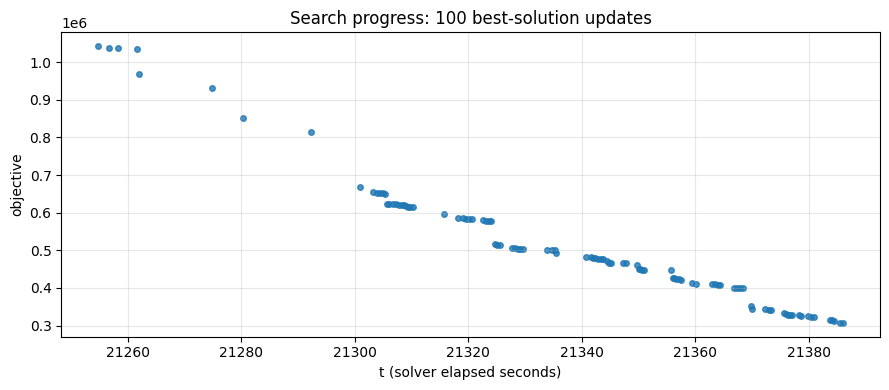

[최선 해 갱신] count=101, objective=306200, t=21386.97s
[최선 해 갱신] count=102, objective=306000, t=21389.04s
[최선 해 갱신] count=103, objective=304900, t=21389.34s
[최선 해 갱신] count=104, objective=304200, t=21389.76s
[최선 해 갱신] count=105, objective=303100, t=21392.93s
[최선 해 갱신] count=106, objective=302400, t=21393.45s
[최선 해 갱신] count=107, objective=301100, t=21393.72s
[최선 해 갱신] count=108, objective=300400, t=21394.25s
[최선 해 갱신] count=109, objective=300200, t=21395.04s
[최선 해 갱신] count=110, objective=297500, t=21395.23s
[최선 해 갱신] count=111, objective=296200, t=21395.78s
[최선 해 갱신] count=112, objective=295500, t=21396.37s
[최선 해 갱신] count=113, objective=294200, t=21396.96s
[최선 해 갱신] count=114, objective=293300, t=21399.67s
[최선 해 갱신] count=115, objective=292700, t=21400.49s
[최선 해 갱신] count=116, objective=292000, t=21400.75s
[최선 해 갱신] count=117, objective=290300, t=21403.44s
[최선 해 갱신] count=118, objective=290000, t=21404.64s
[최선 해 갱신] count=119, objective=286000, t=21406.20s
[최선 해 갱신] count=120, objective=

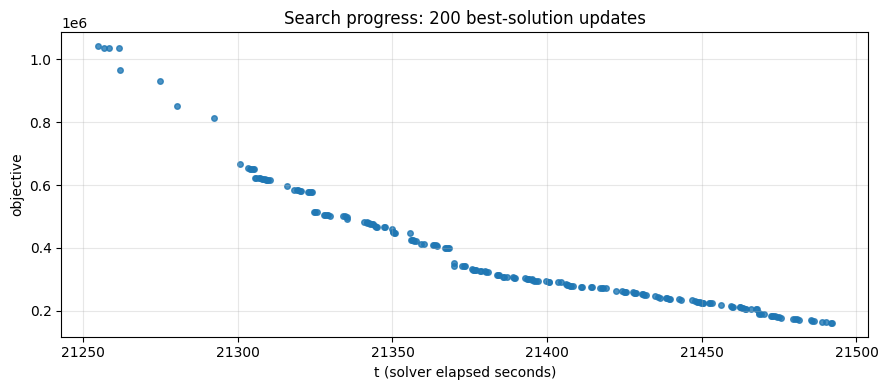

[최선 해 갱신] count=201, objective=161100, t=21492.89s
[최선 해 갱신] count=202, objective=160800, t=21494.29s
[최선 해 갱신] count=203, objective=160100, t=21496.47s
[최선 해 갱신] count=204, objective=159800, t=21496.80s
[최선 해 갱신] count=205, objective=159100, t=21497.67s
[최선 해 갱신] count=206, objective=157800, t=21498.25s
[최선 해 갱신] count=207, objective=156900, t=21501.16s
[최선 해 갱신] count=208, objective=155600, t=21501.76s
[최선 해 갱신] count=209, objective=155300, t=21502.35s
[최선 해 갱신] count=210, objective=154000, t=21502.92s
[최선 해 갱신] count=211, objective=153700, t=21503.53s
[최선 해 갱신] count=212, objective=153100, t=21506.74s
[최선 해 갱신] count=213, objective=152800, t=21507.30s
[최선 해 갱신] count=214, objective=135900, t=21509.26s
[최선 해 갱신] count=215, objective=134600, t=21509.56s
[최선 해 갱신] count=216, objective=133400, t=21509.90s
[최선 해 갱신] count=217, objective=133300, t=21510.07s
[최선 해 갱신] count=218, objective=132100, t=21510.37s
[최선 해 갱신] count=219, objective=131500, t=21515.11s
[최선 해 갱신] count=220, objective=

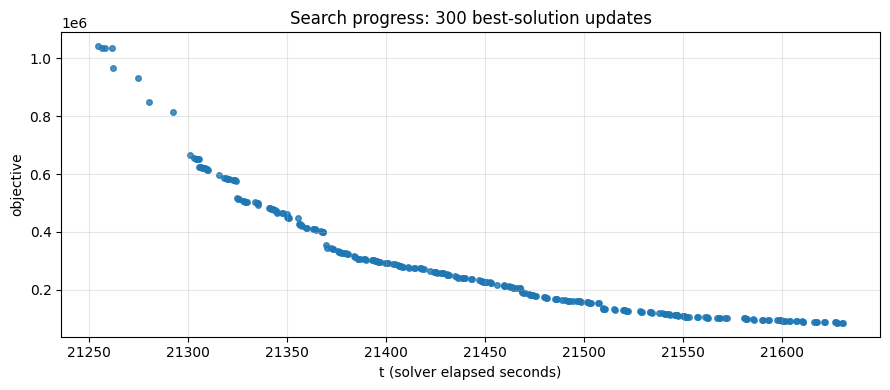

[최선 해 갱신] count=301, objective=84700, t=21632.99s
[최선 해 갱신] count=302, objective=84400, t=21633.35s
[최선 해 갱신] count=303, objective=84100, t=21633.59s
[최선 해 갱신] count=304, objective=83800, t=21633.87s
[최선 해 갱신] count=305, objective=83500, t=21634.15s
[최선 해 갱신] count=306, objective=83200, t=21634.71s
[최선 해 갱신] count=307, objective=82900, t=21635.19s
[최선 해 갱신] count=308, objective=82600, t=21636.67s
[최선 해 갱신] count=309, objective=82300, t=21637.17s
[최선 해 갱신] count=310, objective=82000, t=21638.47s
[최선 해 갱신] count=311, objective=81700, t=21638.75s
[최선 해 갱신] count=312, objective=81400, t=21644.92s
[최선 해 갱신] count=313, objective=81100, t=21645.20s
[최선 해 갱신] count=314, objective=80800, t=21645.95s
[최선 해 갱신] count=315, objective=80500, t=21648.53s
[최선 해 갱신] count=316, objective=79900, t=21654.63s
[최선 해 갱신] count=317, objective=78900, t=21655.68s
[최선 해 갱신] count=318, objective=78600, t=21656.02s
[최선 해 갱신] count=319, objective=78300, t=21656.41s
[최선 해 갱신] count=320, objective=78000, t=21656.99s


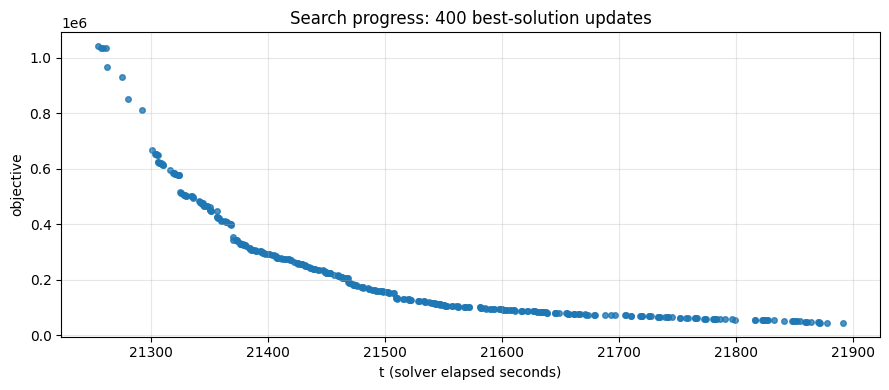

[최선 해 갱신] count=401, objective=44500, t=21892.70s
[최선 해 갱신] count=402, objective=44200, t=21893.10s
[최선 해 갱신] count=403, objective=43200, t=21900.74s
[최선 해 갱신] count=404, objective=42900, t=21907.30s
[최선 해 갱신] count=405, objective=42600, t=21907.67s
[최선 해 갱신] count=406, objective=42300, t=21908.07s
[최선 해 갱신] count=407, objective=42000, t=21908.49s
[최선 해 갱신] count=408, objective=41700, t=21909.26s
[최선 해 갱신] count=409, objective=41400, t=21909.90s
[최선 해 갱신] count=410, objective=41100, t=21911.26s
[최선 해 갱신] count=411, objective=40100, t=21912.14s
[최선 해 갱신] count=412, objective=39800, t=21919.88s
[최선 해 갱신] count=413, objective=39500, t=21945.20s
[최선 해 갱신] count=414, objective=39200, t=21945.75s
[최선 해 갱신] count=415, objective=38900, t=21949.00s
[최선 해 갱신] count=416, objective=38200, t=21958.62s
[최선 해 갱신] count=417, objective=37900, t=21958.90s
[최선 해 갱신] count=418, objective=37600, t=21959.50s
[최선 해 갱신] count=419, objective=37300, t=21966.36s
[최선 해 갱신] count=420, objective=37000, t=21970.77s


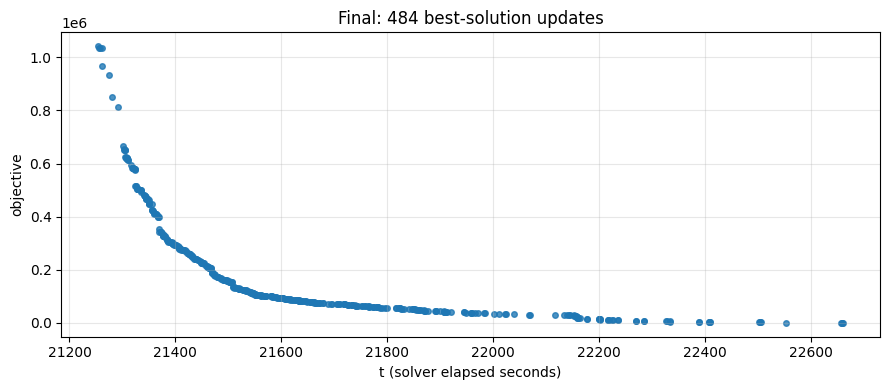

[5/8] Solver 탐색 종료
  상태: OPTIMAL
  소요 시간: 22664.28초
  탐색 내부 충돌 수 (시간표 중복 건수 아님): 16402318
  분기 수: 152826429
[6/8] 결과 정리 시작
[6/8] 결과 정리 완료
[7/8] 엑셀 파일 저장 시작
[8/8] 엑셀 파일 저장 완료
결과 파일: /content/drive/MyDrive/2025_1_tuning/result/2025_1_result_v5.xlsx


In [4]:
# 입력만 사용한다. 최선 해 100회 갱신마다, 그리고 종료 시 산점도를 출력한다.
base = Path("/content/drive/MyDrive/2025_1_tuning")
solve_timetable(
    excel_path=str(base / "input/2025_1_input_mannual.xlsx"),
    output_path=str(base / "result/2025_1_result_v5.xlsx"),
    time_limit_seconds=1000000,
    first_solution_only=False,
    log_search_progress=True,
)
